In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
import pandas as pd

In [3]:
T = 24 # Time periods
nb = 5 # Buses
nl = 4 # Lines
ng = 3 # Generators

In [4]:
# Generator-to-bus mapping
G = np.array([
    [1, 0, 0],
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [0, 0, 0]
])

# Line-to-bus mapping
K = np.array([
    [1, -1, 0, 0, 0],
    [1, 0, -1, 0, 0],
    [0, 0, 1, -1, 0],
    [0, 0, 0, 1, -1]
]).T

In [5]:
def load_func(day, temp):
    gamma = 1.0 if day in [0, 1, 2, 3, 4] else 0.8
    baseline = gamma * 1000 * np.ones(T)
    cooling = 0.5 * (temp + np.random.randn(T)**2 - 65).clip(0) ** 2 
    return baseline + cooling

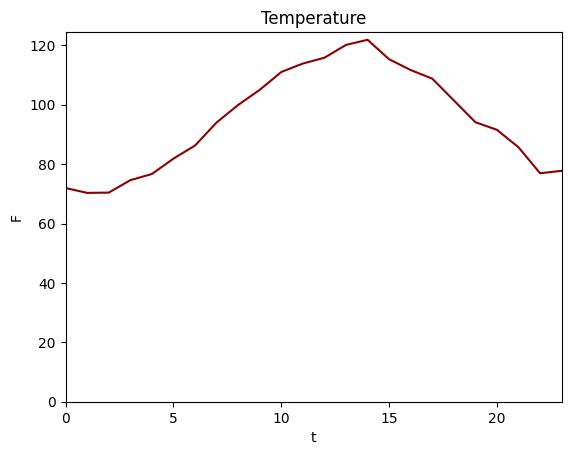

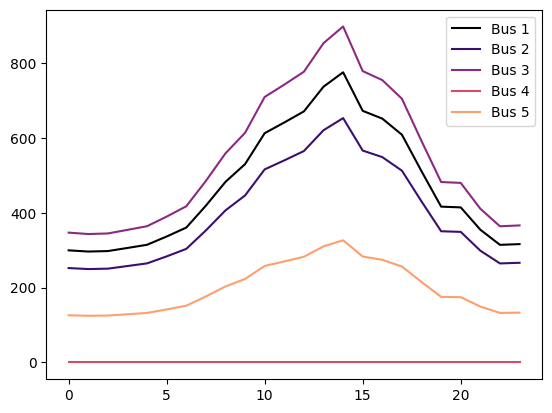

Total Peak Demand: 2652.72 MW
Total Generation Capacity: 1975 MW
Total Transmission Capacity: 1975 MW


In [6]:
# Time
time = np.arange(24)

# Temperature
alpha = 0.8 + 0.5 * np.random.rand()
temp = alpha * 95 * (np.sin(2 * np.pi * time / T - 3 * np.pi / 5) + 4) / 5
temp += 1.5 * np.random.randn(24)

plt.title("Temperature")
plt.plot(time, temp, color="darkred")
plt.xlabel("t")
plt.ylabel("F")
plt.axis([0, T-1, 0, None])
plt.show()

# Load
day = np.random.randint(7)
load_shape = load_func(day, temp)
demand_share = np.array([95, 80, 110, 0, 40])
demand_share = demand_share / demand_share.sum()
load = (demand_share * load_shape.reshape(-1, 1)).T

# Plot load shapes
cmap = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [cmap(i/5) for i in range(nb)]
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.show()

# Print total peak demand
print(f"Total Peak Demand: {load.max(axis=1).sum():.2f} MW")

# Generation
cost = np.array([50, 80, 30])
pmax = np.array([550, 800, 625])
print(f"Total Generation Capacity: {pmax.sum()} MW")

# Lines
fmax = np.array([600, 450, 500, 425])
print(f"Total Transmission Capacity: {fmax.sum()} MW")

# VoLL
voll = 10000 # $/MWh - baseline VoLL

# Reshape data
cost = np.tile(cost[:, None], (1, T))
pmax = np.tile(pmax[:, None], (1, T))
fmax = np.tile(fmax[:, None], (1, T))

In [7]:
# CVXPY Model

# Variables
p = cp.Variable((ng, T), nonneg=True)
f = cp.Variable((nl, T))
u = cp.Variable((nb, T), nonneg=True)

# Parameters
c = cp.Parameter((ng, T), nonneg=True)
c.value = cost
v = cp.Parameter((nb, T), nonneg=True) # Static VoLL
v.value = voll * np.ones((nb, T))
d = cp.Parameter((nb, T), nonneg=True) # Demand
d.value = load

# Objectives
total_ue = cp.sum(u)
gen_costs = cp.sum(cp.multiply(c, p))
ue_costs = cp.sum(cp.multiply(v, u))

# Constraints
constraints = [
    G @ p + K @ f == d - u,
    p <= pmax,
    f <= fmax,
    f >= -fmax,
    u <= d,
]

# Problem
cost_problem = cp.Problem(cp.Minimize(gen_costs + ue_costs), constraints)
ue_problem = cp.Problem(cp.Minimize(total_ue), constraints)

# Solve
min_cost = cost_problem.solve("GUROBI")
print(min_cost)

min_ue = ue_problem.solve("GUROBI")
print(min_ue)

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2819194
Academic license 2819194 - for non-commercial use only - registered to ch___@berkeley.edu
27701762.118626732
2592.4164497476786


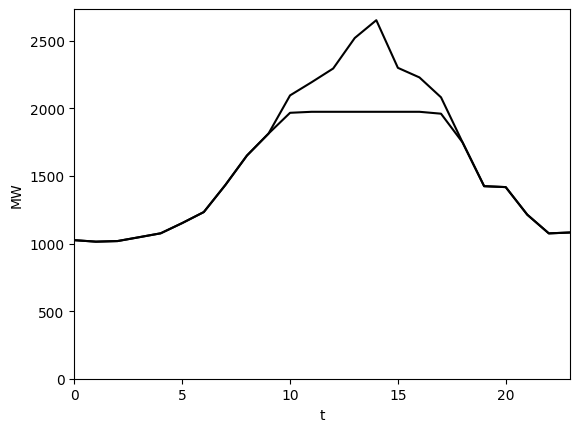

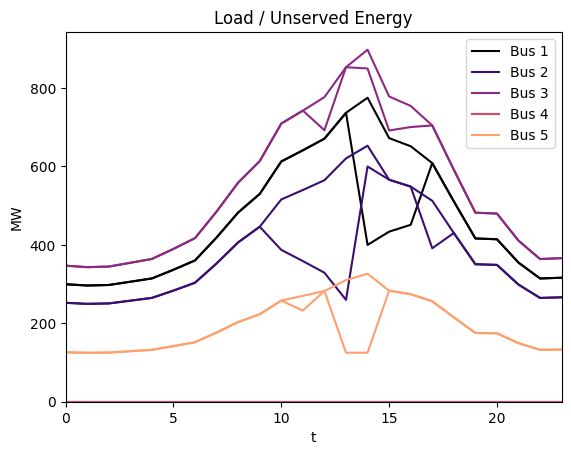

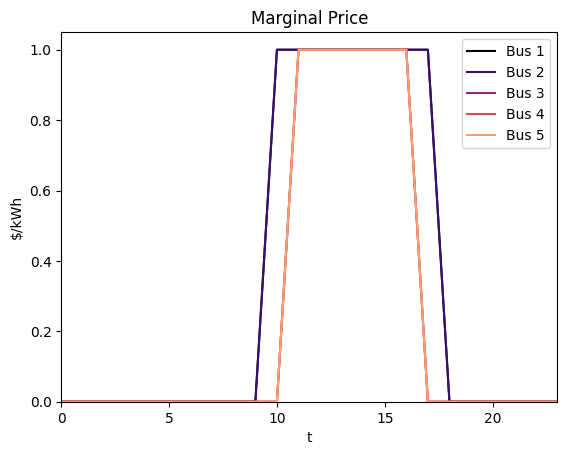

In [11]:
magma = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [magma(i/5) for i in range(nb)]

# Plot total unserved energy
plt.plot(time, np.sum(load, axis=0), color="black", label="Total")
plt.plot(time, np.sum(load - u.value, axis=0), color="black")
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot unserved energy by bus
plt.title("Load / Unserved Energy")
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
    plt.plot(time, load[i,:] - u[i, :].value, color=colors[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot risk by bus
lmp = -constraints[0].dual_value
plt.title("Marginal Price")
for i in range(nb):
    plt.plot(time, lmp[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

In [9]:
# Create training data

def sample_temp():
    alpha = 0.8 + 0.5 * np.random.rand()
    temp = alpha * 95 * (np.sin(2 * np.pi * time / T - 3 * np.pi / 5) + 4) / 5
    temp += 1.5 * np.random.randn(24)
    return temp

def cost_func(load_shape):
    load = (demand_share * load_shape.reshape(-1, 1)).T
    d.value = load
    return cost_problem.solve("GUROBI")

def ue_func(load_shape):
    load = (demand_share * load_shape.reshape(-1, 1)).T
    d.value = load
    return ue_problem.solve("GUROBI")

def get_duals():
    duals = -constraints[0].dual_value
    return duals.T @ demand_share

def get_ue():
    return u.value.sum()

In [ ]:
# Set seed to 10
np.random.seed(10)
# Number of samples
N = 5000

# Sample temperature, load, cost, duals
time_cols = list(np.arange(T))
input_cols = ["day"] + time_cols
input_df = pd.DataFrame(index=np.arange(N), columns=input_cols)
load_df = pd.DataFrame(index=np.arange(N), columns=time_cols)
cost_df = pd.DataFrame(index=np.arange(N), columns=["cost"])
duals_df = pd.DataFrame(index=np.arange(N), columns=time_cols)
ue_df = pd.DataFrame(index=np.arange(N), columns=["ue"])
for i in range(5000):
    day = i % 7
    temp = sample_temp()
    input_df.loc[i,"day"] = day
    input_df.loc[i,time_cols] = temp
    load = load_func(day, temp)
    load_df.loc[i,time_cols] = load
    cost = cost_func(load)
    cost_df.loc[i,"cost"] = cost
    duals = get_duals()
    duals_df.loc[i,time_cols] = duals
    ue = get_ue()
    ue_df.loc[i,"ue"] = ue

In [ ]:
# Save data for training
input_df.to_csv("training/input.csv", index=False)
load_df.to_csv("training/load.csv", index=False)
cost_df.to_csv("training/cost.csv", index=False)
duals_df.to_csv("training/duals.csv", index=False)
ue_df.to_csv("training/ue.csv", index=False)

In [12]:
# Read in training data
input_df = pd.read_csv("training/input.csv")
load_df = pd.read_csv("training/load.csv")
cost_df = pd.read_csv("training/cost.csv")
duals_df = pd.read_csv("training/duals.csv")
ue_df = pd.read_csv("training/ue.csv")

In [13]:
import torch

class MinCostLayer(torch.autograd.Function):

    @staticmethod
    def forward(ctx, load_batch):
        costs = []
        duals_batch = []
        for load_shape in load_batch:
            # Get load shape
            load_np = load_shape.detach().cpu().numpy()
            # Compute optimal cost
            cost = cost_func(load_np)
            # Extract duals
            duals = get_duals()
            # Save
            costs.append(float(cost))
            duals_batch.append(np.asarray(duals).reshape(load_shape.shape))

        # Store duals as tensor for backwards pass
        duals_tensor = torch.as_tensor(
            np.stack(duals_batch),
            dtype=load_batch.dtype,
            device=load_batch.device,
        )
        ctx.save_for_backward(duals_tensor)

        return load_batch.new_tensor(costs)

    @staticmethod
    def backward(ctx, grad_output):
        (duals_batch,) = ctx.saved_tensors
        return grad_output.unsqueeze(-1) * duals_batch

class MinUnservedEnergyLayer(torch.autograd.Function):

    @staticmethod
    def forward(ctx, load_batch):
        ues = []
        duals_batch = []
        for load_shape in load_batch:
            # Get load shape
            load_np = load_shape.detach().cpu().numpy()
            # Compute minimum unserved energy
            ue = ue_func(load_np)
            # Extract duals
            duals = get_duals()
            # Save
            ues.append(float(ue))
            duals_batch.append(np.asarray(duals).reshape(load_shape.shape))

        # Store duals as tensor for backwards pass
        duals_tensor = torch.as_tensor(
            np.stack(duals_batch),
            dtype=load_batch.dtype,
            device=load_batch.device,
        )
        ctx.save_for_backward(duals_tensor)

        return load_batch.new_tensor(ues)

    @staticmethod
    def backward(ctx, grad_output):
        (duals_batch,) = ctx.saved_tensors
        return grad_output.unsqueeze(-1) * duals_batch

In [55]:
# PyTorch: train neural network to predict load shape from temperature
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(25)

n_train = int(0.7 * len(input_df))
input_df_train, input_df_val = input_df.iloc[:n_train], input_df.iloc[n_train:]
load_df_train, load_df_val = load_df.iloc[:n_train], load_df.iloc[n_train:]
cost_df_train, cost_df_val = cost_df.iloc[:n_train], cost_df.iloc[n_train:]
ue_df_train, ue_df_val = ue_df.iloc[:n_train], ue_df.iloc[n_train:]

input_train = torch.tensor(input_df_train.to_numpy(), dtype=torch.float32)
input_val   = torch.tensor(input_df_val.to_numpy(), dtype=torch.float32)
load_train = torch.tensor(load_df_train.to_numpy(), dtype=torch.float32)
load_val   = torch.tensor(load_df_val.to_numpy(), dtype=torch.float32)
cost_train = torch.tensor(cost_df_train.to_numpy(), dtype=torch.float32)
cost_val   = torch.tensor(cost_df_val.to_numpy(), dtype=torch.float32)
ue_train = torch.tensor(ue_df_train.to_numpy(), dtype=torch.float32)
ue_val   = torch.tensor(ue_df_val.to_numpy(), dtype=torch.float32)

# Normalize using training-set statistics only
input_mean, input_std = input_train.mean(dim=0), input_train.std(dim=0).clamp(min=1e-8)
load_mean, load_std = load_train.mean(dim=0), load_train.std(dim=0).clamp(min=1e-8)
cost_mean, cost_std = cost_train.mean(dim=0), cost_train.std(dim=0).clamp(min=1e-8)
ue_mean, ue_std = ue_train.mean(dim=0), ue_train.std(dim=0).clamp(min=1e-8)

input_train = (input_train - input_mean) / input_std
input_val = (input_val - input_mean) / input_std
load_train = (load_train - load_mean) / load_std
load_val = (load_val - load_mean) / load_std
cost_train = (cost_train - cost_mean) / cost_std
cost_val = (cost_val - cost_mean) / cost_std
ue_train = (ue_train - ue_mean) / ue_std
ue_val = (ue_val - ue_mean) / ue_std

# Data loader
train_loader = DataLoader(
    TensorDataset(input_train, load_train, cost_train, ue_train),
    batch_size=32,
    shuffle=True
)

# Neural network: input_dim=25 -> 64 -> 64 -> 24 -> 1
load_model = nn.Sequential(
    nn.Linear(25, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 24),
)

optimizer = torch.optim.Adam(load_model.parameters(), lr=1e-3)
loss_func = nn.MSELoss()

# Train
n_epochs = 120
start_epoch = 110
use_cost = True
use_ue = True

for epoch in range(n_epochs):
    load_model.train()
    train_loss = 0.0
    for input_batch, load_batch, cost_batch, ue_batch in train_loader:
        optimizer.zero_grad()
        load_pred = load_model(input_batch)
        load_loss = loss_func(load_batch, load_pred)
        loss = load_loss
        if epoch >= start_epoch and use_cost:
            load_pred_phys = (load_pred * load_std + load_mean).clamp(min=0.0)
            cost_pred_phys = MinCostLayer.apply(load_pred_phys)
            cost_pred = (cost_pred_phys - cost_mean.squeeze()) / cost_std.squeeze()
            cost_batch = cost_batch.reshape(-1)
            cost_loss = loss_func(cost_batch, cost_pred)
            loss = loss + cost_loss
        if epoch >= start_epoch and use_ue:
            load_pred_phys = (load_pred * load_std + load_mean).clamp(min=0.0)
            ue_pred_phys = MinUnservedEnergyLayer.apply(load_pred_phys)
            ue_pred = (ue_pred_phys - ue_mean.squeeze()) / ue_std.squeeze()
            ue_batch = ue_batch.reshape(-1)
            ue_loss = loss_func(ue_batch, ue_pred)
            loss = loss + ue_loss
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(input_batch)

    train_loss /= len(input_train)

    load_model.eval()
    with torch.no_grad():
        val_loss = loss_func(load_model(input_val), load_val).item()

    if (epoch + 1) % 10 == 0 or (epoch >= start_epoch):
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Val MSE: {val_loss:.4f}"
        )

# Predict load shapes in original units
load_model.eval()
with torch.no_grad():
    load_pred = load_model(input_val) * load_std + load_mean

df_loadpred = pd.DataFrame(
    load_pred.numpy(),
    index=load_df_val.index,
    columns=load_df_val.columns
)

df_loadval = load_df_val.copy()

Epoch  10 | Train MSE: 0.0443 | Val MSE: 0.0429
Epoch  20 | Train MSE: 0.0273 | Val MSE: 0.0254
Epoch  30 | Train MSE: 0.0246 | Val MSE: 0.0232
Epoch  40 | Train MSE: 0.0221 | Val MSE: 0.0228
Epoch  50 | Train MSE: 0.0206 | Val MSE: 0.0189
Epoch  60 | Train MSE: 0.0194 | Val MSE: 0.0184
Epoch  70 | Train MSE: 0.0180 | Val MSE: 0.0173
Epoch  80 | Train MSE: 0.0178 | Val MSE: 0.0175
Epoch  90 | Train MSE: 0.0172 | Val MSE: 0.0166
Epoch 100 | Train MSE: 0.0169 | Val MSE: 0.0164
Epoch 110 | Train MSE: 0.0168 | Val MSE: 0.0160
Epoch 111 | Train MSE: 0.0869 | Val MSE: 0.0199
Epoch 112 | Train MSE: 0.0519 | Val MSE: 0.0194
Epoch 113 | Train MSE: 0.0515 | Val MSE: 0.0197
Epoch 114 | Train MSE: 0.0566 | Val MSE: 0.0178
Epoch 115 | Train MSE: 0.0514 | Val MSE: 0.0182
Epoch 116 | Train MSE: 0.0454 | Val MSE: 0.0178
Epoch 117 | Train MSE: 0.0401 | Val MSE: 0.0175
Epoch 118 | Train MSE: 0.0403 | Val MSE: 0.0176
Epoch 119 | Train MSE: 0.0401 | Val MSE: 0.0166
Epoch 120 | Train MSE: 0.0375 | Val MSE:

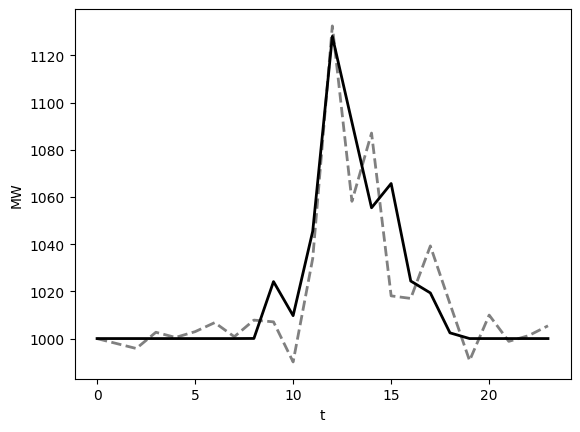

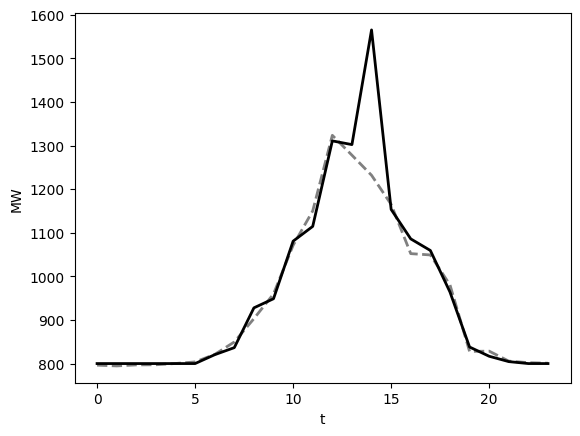

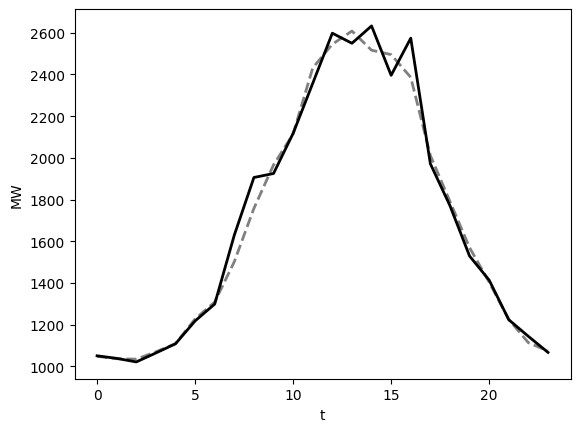

In [56]:
# Plot a few examples of load predictions
plt.plot(time, df_loadpred.loc[3500,:], color="grey", linestyle="--", linewidth=2.0)
plt.plot(time, df_loadval.loc[3500,:], color="black", linestyle="-", linewidth=2.0)
plt.xlabel("t")
plt.ylabel("MW")
plt.show()

# Plot a few examples
plt.plot(time, df_loadpred.loc[3800,:], color="grey", linestyle="--", linewidth=2.0)
plt.plot(time, df_loadval.loc[3800,:], color="black", linestyle="-", linewidth=2.0)
plt.xlabel("t")
plt.ylabel("MW")
plt.show()

# Plot a few examples
plt.plot(time, df_loadpred.loc[4200,:], color="grey", linestyle="--", linewidth=2.0)
plt.plot(time, df_loadval.loc[4200,:], color="black", linestyle="-", linewidth=2.0)
plt.xlabel("t")
plt.ylabel("MW")
plt.show()

In [57]:
# Get cost predictions
df_costval = cost_df.loc[df_loadval.index]
df_costpred = pd.DataFrame(index=df_loadval.index, columns=["cost"])
df_ueval = ue_df.loc[df_loadval.index]
df_uepred = pd.DataFrame(index=df_loadval.index, columns=["ue"])
for i in df_loadval.index:
    load_pred = df_loadpred.loc[i,:].values
    cost = cost_func(load_pred)
    ue = get_ue()
    df_costpred.loc[i,"cost"] = cost
    df_uepred.loc[i,"ue"] = ue

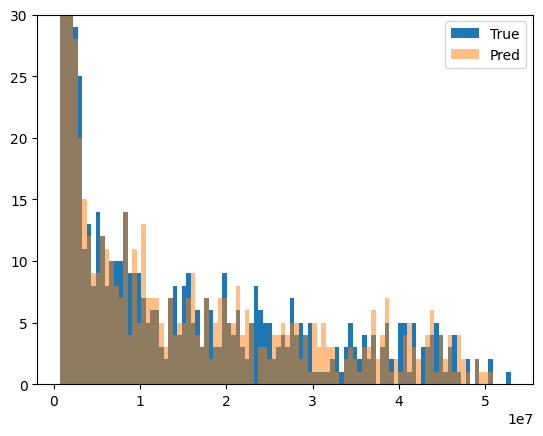

In [58]:
_, bins, _ = plt.hist(df_costval, bins=100, label="True")
plt.hist(df_costpred, bins=bins, alpha=0.5, label="Pred")
plt.axis([None, None, 0, 30])
plt.legend()
plt.show()

In [59]:
cost_rmse = np.sqrt(np.mean((df_costval - df_costpred)**2))
cost_mean = np.mean(df_costval)

ue_rmse = np.sqrt(np.mean((df_ueval - df_uepred)**2))
ue_mean = np.mean(df_ueval)

print(f"Cost NRMSE: 100% x ${cost_rmse:.0f} / ${cost_mean:.0f} = {100 * cost_rmse/cost_mean:.1f}%")
print(f"UE NRMSE: 100% x {ue_rmse:.0f} MWh / {ue_mean:.0f} MWh = {100 * ue_rmse/ue_mean:.1f}%")
print(f"Predicted EUE: {np.mean(df_uepred):.0f} MWh | Actual EUE: {ue_mean:.0f} MWh")

Cost NRMSE: 100% x $1027486 / $6455164 = 15.9%
UE NRMSE: 100% x 103 MWh / 522 MWh = 19.7%
Predicted EUE: 522 MWh | Actual EUE: 522 MWh


### Vanilla NN

Cost NRMSE: 100% x \\$1024118 / \\$6455164 = 15.9%

UE NRMSE: 100% x 102 MWh / 522 MWh = 19.6%

Predicted EUE: 510 MWh | Actual EUE: 522 MWh

### Cost-Aware NN (10 epochs)

Cost NRMSE: 100% x \\$1045729 / \\$6455164 = 16.2%

UE NRMSE: 100% x 104 MWh / 522 MWh = 20.0%

Predicted EUE: 527 MWh | Actual EUE: 522 MWh

### UE-Aware NN (10 epochs)

Cost NRMSE: 100% x \\$1038721 / \\$6455164 = 16.1%

UE NRMSE: 100% x 104 MWh / 522 MWh = 19.9%

Predicted EUE: 526 MWh | Actual EUE: 522 MWh

### Cost-and-UE-Aware NN (10 epochs)

Cost NRMSE: 100% x \\$1027486 / \\$6455164 = 15.9%

UE NRMSE: 100% x 103 MWh / 522 MWh = 19.7%

Predicted EUE: 522 MWh | Actual EUE: 522 MWh